# Tutorial 7 — Van Gurp–Palmen and Cole–Cole plots

This tutorial demonstrates two rheology-specific visualizations in
in [`hermes_rheo.visualization`](../src/hermes_rheo/visualization/visualize.py) tfor diagnosing time-temperature superposition (tTS).

| Function | x-axis | y-axis | Scale |
|---|---|---|---|
| `plot_vgp` | $|G^*|$ (complex modulus) | $\tan(\delta)$ | x: log |
| `plot_cole_cole` | $G'$ (storage modulus) | $G''$ (loss modulus) | x+y: log |

:::{seealso}
- **van Gurp–Palmen (vGP)** plot: van Gurp, M. & Palmen, J. (1998),
  *Time-temperature superposition for polymeric blends*, Rheology
  Bulletin **67**(1), 5–8.
- **Cole–Cole** plot: Cole, K. S. & Cole, R. H. (1941), *Dispersion and
  Absorption in Dielectrics — I. Alternating Current Characteristics*,
  J. Chem. Phys. **9**(4), 341–351.
  DOI: [`10.1063/1.1750906`](https://doi.org/10.1063/1.1750906).
:::


In [1]:
import os

import matplotlib.pyplot as plt

from hermes_rheo import read_file
from hermes_rheo.file_readers.trios_rheo_txt import TriosRheoReader
from hermes_rheo.transforms.owchirp_analysis import OWChirpAnalysis
from hermes_rheo.visualization import plot_vgp, plot_cole_cole

# Publication-quality Matplotlib styling — 'science' + 'notebook' with
# LaTeX disabled so the style works on any machine.
from hermes_rheo.visualization import use_science_style
use_science_style()

%matplotlib inline

current_dir = os.path.dirname(os.path.abspath("__file__"))

## 1. Frequency-sweep time-Temperature superposition data

In [2]:
filepath_fs = os.path.join(
    current_dir, "tutorial_data", "tutorial_4", "frequency_sweep_tts.txt"
)
experiment_fs = read_file(
    filepath=filepath_fs,
    file_reader=TriosRheoReader,
    create_composite_datasets=True,
)
#print(experiment_fs)

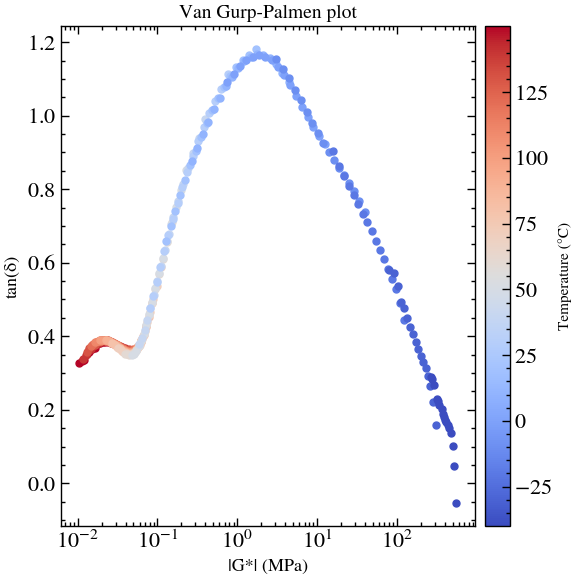

In [3]:
fig, ax = plot_vgp(experiment_fs)
plt.show()


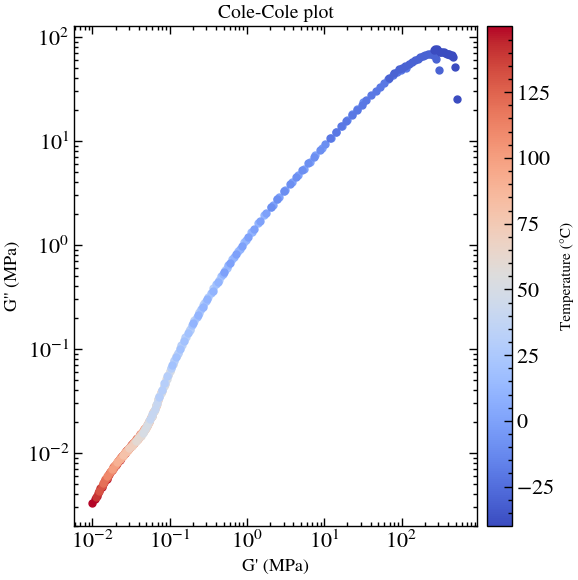

In [4]:
fig, ax = plot_cole_cole(experiment_fs)
plt.show()


## 2. OWChirp TTS data

OWChirp data are collected as raw transient stress/strain signals, so
`OWChirpAnalysis` (Geri *et al.* 2018) is applied first to compute
$G'$, $G''$, $|G^*|$ and $\tan(\delta)$ before feeding the result to
the vGP / Cole–Cole plotters.

In [5]:
filepath_chirp = os.path.join(
    current_dir, "tutorial_data", "tutorial_4", "owchirp_tts.txt"
)

experiment_chirp = read_file(
    filepath=filepath_chirp,
    file_reader=TriosRheoReader,
    create_composite_datasets=True,
)

# OWChirpAnalysis computes G', G'', |G*|, tan(delta) from the raw signal.
pipeline = OWChirpAnalysis()
experiment_chirp_analysed = pipeline(experiment_chirp)
#print(experiment_chirp_analysed)

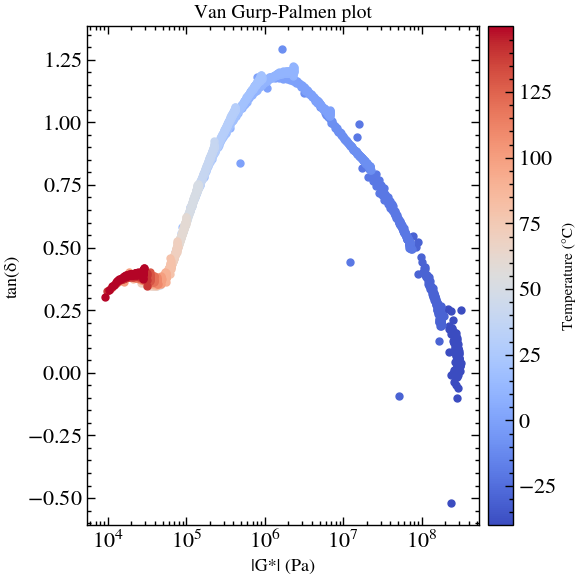

In [6]:
fig, ax = plot_vgp(experiment_chirp_analysed)
plt.show()


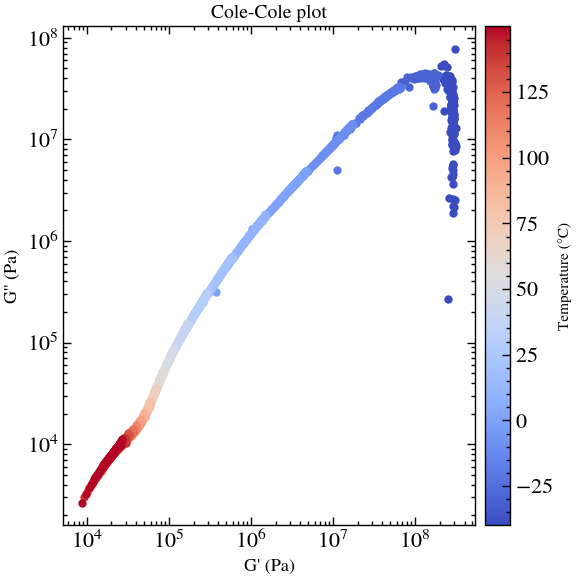

In [7]:
fig, ax = plot_cole_cole(experiment_chirp_analysed)
plt.show()


## 3. TORCh (Thermally-Optimised Ramped Chirp) data

A larger, temperature-swept multi-chirp dataset — same API, no extra
processing needed for the vGP/Cole–Cole plotters (the fixture already
carries pre-computed moduli).

In [8]:
filepath_torch = os.path.join(
    current_dir, "tutorial_data", "tutorial_7", "torch.txt"
)
experiment_torch = read_file(
    filepath=filepath_torch,
    file_reader=TriosRheoReader,
    create_composite_datasets=True,
)
#print(experiment_torch)

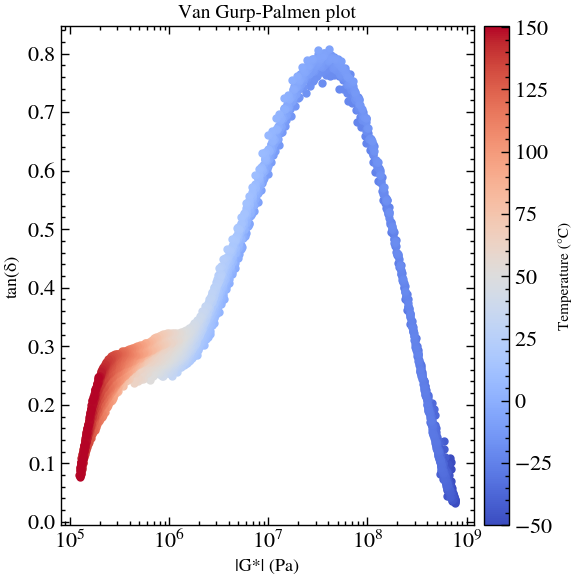

In [9]:
fig, ax = plot_vgp(experiment_torch)
plt.show()


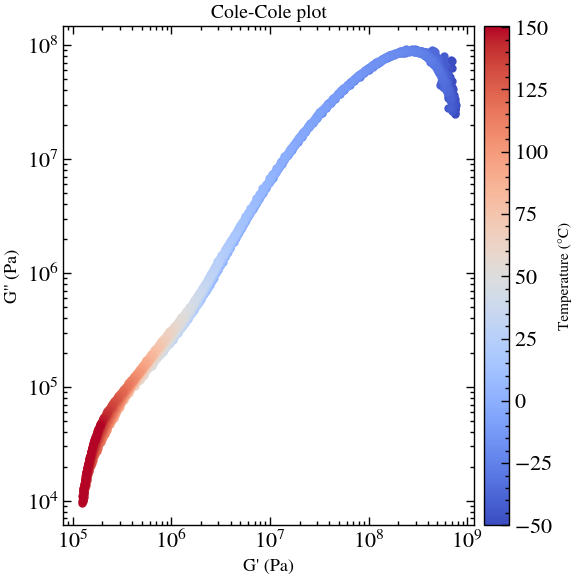

In [10]:
fig, ax = plot_cole_cole(experiment_torch)
plt.show()


## 4. Customisation examples

Pass any `ax.plot` keyword to override the defaults (marker, markersize, colormap, etc.).


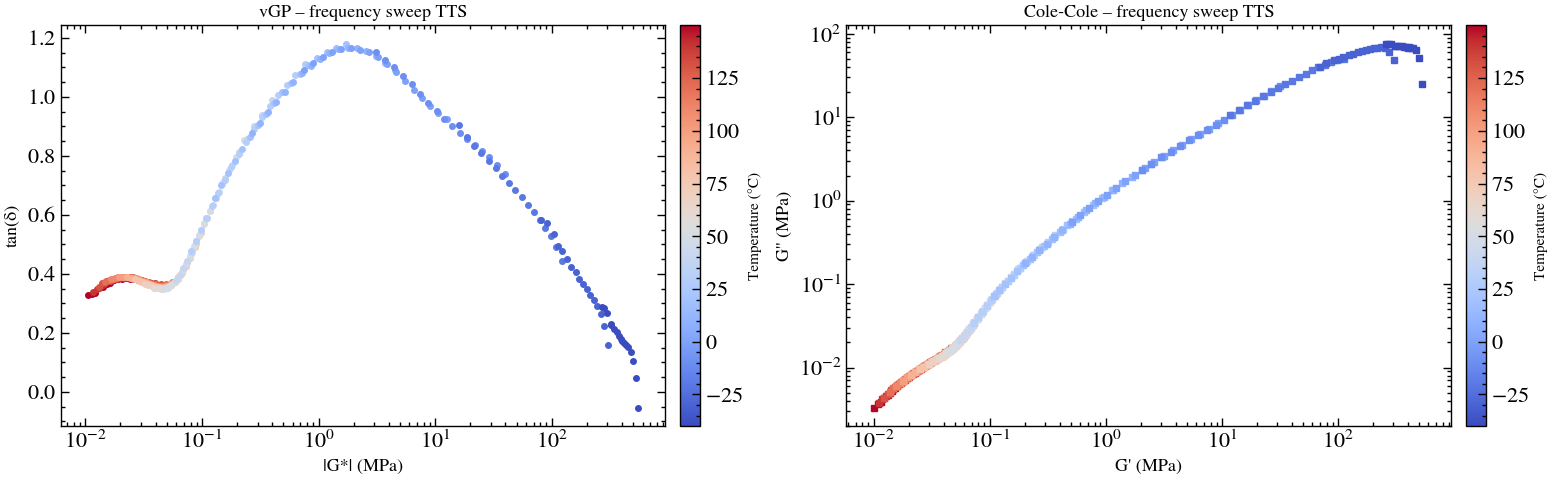

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

plot_vgp(experiment_fs, ax=axes[0], marker='o', markersize=4)
axes[0].set_title('vGP – frequency sweep TTS', fontsize=13)

plot_cole_cole(experiment_fs, ax=axes[1], marker='s', markersize=4)
axes[1].set_title('Cole-Cole – frequency sweep TTS', fontsize=13)

plt.tight_layout()
plt.show()
